# LAB 04 - Text Classification (IMDb Sentiment)

Bài toán: phân loại cảm xúc review phim IMDb thành positive / negative (Option A - Sentiment classification).

Pipeline: raw text -> preprocessing -> representation (TF-IDF / Average Word2Vec) -> classifier (Logistic Regression / Linear SVM) -> prediction -> evaluation -> error analysis.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from gensim.models import Word2Vec

import preprocessing as pp

SEED = pp.SEED
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 200)

## 1. Experiment 1 - Dataset inspection

In [2]:
raw = pp.load_imdb()
info = pp.inspect(raw)
info

{'n_samples': 50000,
 'n_classes': 2,
 'class_count': {'positive': 25000, 'negative': 25000},
 'class_pct': {'positive': 50.0, 'negative': 50.0},
 'missing_text': 0,
 'missing_label': 0,
 'duplicate_docs': 418,
 'len_mean': 231.15694,
 'len_median': 173.0,
 'len_min': 4,
 'len_max': 2470}

In [3]:
dist = pd.DataFrame({"Count": raw["sentiment"].value_counts()})
dist["Percentage"] = (dist["Count"] / dist["Count"].sum() * 100).round(2)
dist

,Count,Percentage
sentiment,,
positive,25000,50.0
negative,25000,50.0


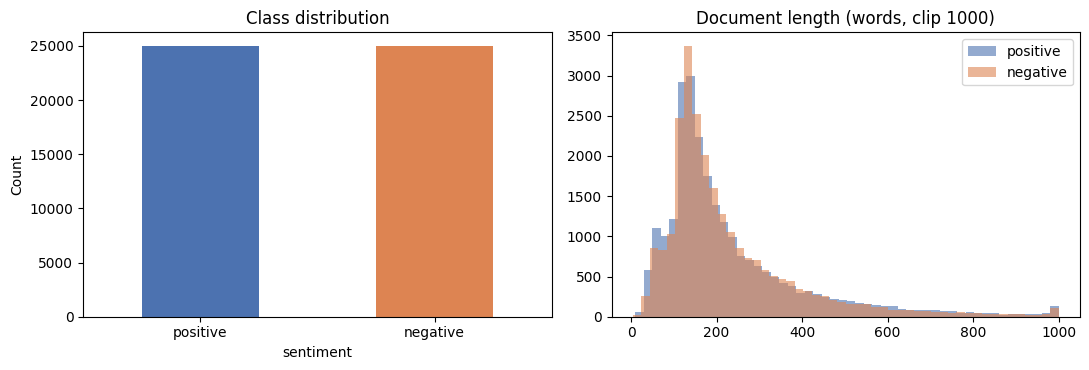

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,25000.0,229.5,164.9,4.0,128.0,174.0,278.0,1522.0
positive,25000.0,232.8,177.5,10.0,125.0,172.0,284.0,2470.0


In [4]:
lengths = raw["review"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
dist["Count"].plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Count")
for lab, color in [("positive", "#4C72B0"), ("negative", "#DD8452")]:
    axes[1].hist(lengths[raw["sentiment"] == lab].clip(upper=1000), bins=50, alpha=0.6, label=lab, color=color)
axes[1].set_title("Document length (words, clip 1000)")
axes[1].legend()
plt.tight_layout()
plt.show()
raw.assign(length=lengths).groupby("sentiment")["length"].describe().round(1)

In [5]:
# Cac review trung lap: co cap nao trung text nhung khac nhan khong?
dup = raw[raw.duplicated(subset="review", keep=False)]
print("So dong thuoc nhom trung lap:", len(dup))
print("So text trung lap nhung mau thuan nhan:", (dup.groupby("review")["sentiment"].nunique() > 1).sum())

So dong thuoc nhom trung lap: 824
So text trung lap nhung mau thuan nhan: 0


Kết luận Experiment 1: dataset có 50000 review, 2 class, positive và negative mỗi class 25000 (50% - 50%) nên không có class imbalance. Không có missing text hay missing label. Có 418 review trùng lặp nguyên văn (không có cặp trùng nào mâu thuẫn nhãn), cần loại bỏ trước khi chia để tránh cùng một review vừa nằm ở train vừa nằm ở test. Việc loại trùng được làm trên text đã làm sạch vì một số review chỉ khác nhau ở thẻ HTML hoặc chữ hoa (thêm 4 review, tổng cộng loại 422). Review khá dài (trung bình khoảng 230 từ) và độ dài hai class gần như giống nhau, nên độ dài không phải tín hiệu phân biệt class.

## 2. Train / Validation / Test split và data leakage

Thứ tự đúng: làm sạch text và loại trùng lặp (xử lý từng document độc lập, không học tham số từ dữ liệu) -> chia train/val/test (70/15/15, stratify) -> fit TF-IDF và Word2Vec chỉ trên TRAIN -> transform val/test -> train model. Validation dùng để chọn hyperparameter C, test chỉ dùng một lần để báo cáo.

Nếu fit TF-IDF trên toàn bộ dataset rồi mới chia thì vocabulary và IDF đã được tính có cả document của test set. Model vì thế được "nhìn thấy" thống kê của test (từ chỉ xuất hiện trong test vẫn có cột feature, IDF của mỗi từ bị kéo theo tần suất trong test), nên kết quả trên test lạc quan hơn so với khi gặp dữ liệu thật sự mới. Đây là data leakage.

In [6]:
df = pp.prepare(raw)
train, val, test = pp.split(df)
print("Sau khi loai trung lap:", len(df))
pd.DataFrame({
    name: [len(d), d["label"].mean().round(4)]
    for name, d in [("train", train), ("val", val), ("test", test)]
}, index=["n_samples", "positive_ratio"])

Sau khi loai trung lap: 49578


,train,val,test
n_samples,34704.0000,7437.0000,7437.0000
positive_ratio,0.5019,0.5019,0.5018


In [7]:
# Kiem tra khong co text nao xuat hien o nhieu split
print(len(set(train.text) & set(test.text)), len(set(train.text) & set(val.text)), len(set(val.text) & set(test.text)))

0 0 0


## 3. Experiment 2 - Baseline: TF-IDF + Logistic Regression

Mô hình: z = wᵀx + b, P(y = 1 | x) = σ(z), dự đoán positive nếu P ≥ 0.5.

In [8]:
def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

def make_tfidf(ngram_range=(1, 1)):
    return TfidfVectorizer(tokenizer=pp.tokenize, token_pattern=None, lowercase=False,
                           ngram_range=ngram_range, min_df=2, sublinear_tf=True)

def select_and_fit(make_clf, X_tr, y_tr, X_va, y_va, Cs=(0.25, 1.0, 4.0)):
    # Chon C tren validation, tra ve model tot nhat va thoi gian train cua model do
    best = None
    for C in Cs:
        clf = make_clf(C)
        t0 = time.perf_counter()
        clf.fit(X_tr, y_tr)
        t = time.perf_counter() - t0
        f1 = f1_score(y_va, clf.predict(X_va))
        print(f"  C={C:<5} val F1={f1:.4f} train time={t:.2f}s")
        if best is None or f1 > best[1]:
            best = (clf, f1, t, C)
    return best

y_tr, y_va, y_te = train["label"].values, val["label"].values, test["label"].values
results = []

In [9]:
t0 = time.perf_counter()
tfidf_uni = make_tfidf((1, 1))
X_tr_uni = tfidf_uni.fit_transform(train["text"])   # fit chi tren train
X_va_uni = tfidf_uni.transform(val["text"])
X_te_uni = tfidf_uni.transform(test["text"])
vec_time_uni = time.perf_counter() - t0

lr_uni, _, lr_time, lr_C = select_and_fit(
    lambda C: LogisticRegression(C=C, solver="liblinear", max_iter=1000), X_tr_uni, y_tr, X_va_uni, y_va)
pred_lr = lr_uni.predict(X_te_uni)
baseline = {"Representation": "TF-IDF (unigram)", "Classifier": "Logistic Regression", "C": lr_C,
            "Vocabulary": len(tfidf_uni.vocabulary_), "Vectorize time (s)": round(vec_time_uni, 2),
            "Train time (s)": round(lr_time, 2), **evaluate(y_te, pred_lr)}
results.append(baseline)
pd.DataFrame([baseline]).round(4)

  C=0.25  val F1=0.8868 train time=1.65s


  C=1.0   val F1=0.9018 train time=2.14s


  C=4.0   val F1=0.9038 train time=2.48s


,Representation,Classifier,C,Vocabulary,Vectorize time (s),Train time (s),Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,4.0,57229,6.4,2.48,0.8986,0.8884,0.9126,0.9003


## 4. Experiment 3 - Representation comparison

Model B: Average Word2Vec + Logistic Regression. Word2Vec (CBOW, 100 chiều) được train chỉ trên các review của tập train để không leakage. Mỗi document = trung bình word vector của các token có trong vocabulary.

In [10]:
tok_tr = [pp.tokenize(t) for t in train["text"]]
tok_va = [pp.tokenize(t) for t in val["text"]]
tok_te = [pp.tokenize(t) for t in test["text"]]

t0 = time.perf_counter()
w2v = Word2Vec(sentences=tok_tr, vector_size=100, window=5, min_count=2, sg=0, epochs=10, workers=4, seed=SEED)
w2v_train_time = time.perf_counter() - t0
X_tr_w2v = pp.average_word2vec(tok_tr, w2v.wv)
X_va_w2v = pp.average_word2vec(tok_va, w2v.wv)
X_te_w2v = pp.average_word2vec(tok_te, w2v.wv)
print("Word2Vec vocabulary:", len(w2v.wv), "| train time: %.1fs" % w2v_train_time)
print("good ->", [w for w, _ in w2v.wv.most_similar("good", topn=8)])
print("bad  ->", [w for w, _ in w2v.wv.most_similar("bad", topn=8)])

Word2Vec vocabulary: 60788 | train time: 50.5s
good -> ['bad', 'decent', 'great', 'cool', 'nice', 'lousy', 'fine', 'solid']
bad  -> ['good', 'terrible', 'horrible', 'awful', 'lousy', 'stupid', 'lame', 'dreadful']


In [11]:
lr_w2v, _, w2v_lr_time, w2v_C = select_and_fit(
    lambda C: LogisticRegression(C=C, max_iter=2000), X_tr_w2v, y_tr, X_va_w2v, y_va)
pred_w2v = lr_w2v.predict(X_te_w2v)
results.append({"Representation": "Avg Word2Vec (100d)", "Classifier": "Logistic Regression", "C": w2v_C,
                "Vocabulary": len(w2v.wv), "Vectorize time (s)": round(w2v_train_time, 2),
                "Train time (s)": round(w2v_lr_time, 2), **evaluate(y_te, pred_w2v)})

svm_uni, _, svm_time, svm_C = select_and_fit(
    lambda C: LinearSVC(C=C), X_tr_uni, y_tr, X_va_uni, y_va, Cs=(0.05, 0.25, 1.0))
pred_svm = svm_uni.predict(X_te_uni)
results.append({"Representation": "TF-IDF (unigram)", "Classifier": "Linear SVM", "C": svm_C,
                "Vocabulary": len(tfidf_uni.vocabulary_), "Vectorize time (s)": round(vec_time_uni, 2),
                "Train time (s)": round(svm_time, 2), **evaluate(y_te, pred_svm)})

cols = ["Representation", "Classifier", "Accuracy", "Precision", "Recall", "F1"]
pd.DataFrame(results)[cols].round(4)

  C=0.25  val F1=0.8539 train time=0.59s


  C=1.0   val F1=0.8544 train time=0.52s


  C=4.0   val F1=0.8556 train time=0.51s


  C=0.05  val F1=0.8969 train time=0.68s


  C=0.25  val F1=0.9034 train time=1.01s


  C=1.0   val F1=0.8990 train time=0.59s


,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,0.8986,0.8884,0.9126,0.9003
1,Avg Word2Vec (100d),Logistic Regression,0.8575,0.8468,0.8741,0.8602
2,TF-IDF (unigram),Linear SVM,0.8996,0.8896,0.9132,0.9012


In [12]:
# Hai representation sai o nhung mau khac nhau den muc nao?
wrong_lr, wrong_w2v = pred_lr != y_te, pred_w2v != y_te
print("Chi TF-IDF sai:", (wrong_lr & ~wrong_w2v).sum(), "| Chi Avg W2V sai:", (~wrong_lr & wrong_w2v).sum(),
      "| Ca hai cung sai:", (wrong_lr & wrong_w2v).sum())

Chi TF-IDF sai: 228 | Chi Avg W2V sai: 534 | Ca hai cung sai: 526


Nhận xét: cùng classifier (Logistic Regression) nhưng đổi representation thì kết quả khác nhau. TF-IDF sparse, lexical, giữ nguyên trọng số của từng term nên classifier học được trực tiếp các từ đặc trưng cảm xúc (great, worst, waste, 7/10...). Average Word2Vec là vector dense 100 chiều mang tính semantic, nhưng good và bad là hàng xóm gần nhất của nhau (vì xuất hiện trong ngữ cảnh giống nhau), và khi lấy trung bình hàng trăm từ của một review dài thì các từ mang cảm xúc bị pha loãng bởi từ trung tính, mất word order, mỗi từ chỉ có một vector bất kể ngữ cảnh, nên kém hơn TF-IDF. Linear SVM trên cùng TF-IDF cho kết quả gần như bằng LR, cho thấy representation ảnh hưởng lớn hơn lựa chọn linear classifier.

## 5. Experiment 4 - Word order

In [13]:
from numpy.linalg import norm
s1, s2 = "this movie is good", "this movie is not good"
v1, v2 = pp.average_word2vec([pp.tokenize(s1), pp.tokenize(s2)], w2v.wv)
print("cosine(avg(S1), avg(S2)) =", round(float(v1 @ v2 / (norm(v1) * norm(v2))), 4))

probe = pd.DataFrame({"text": [s1, s2, "this movie is bad", "this movie is not bad"]})
probe["P(pos) TF-IDF uni LR"] = lr_uni.predict_proba(tfidf_uni.transform(probe["text"]))[:, 1]
probe["P(pos) AvgW2V LR"] = lr_w2v.predict_proba(pp.average_word2vec([pp.tokenize(t) for t in probe["text"]], w2v.wv))[:, 1]
probe.round(3)

cosine(avg(S1), avg(S2)) = 0.9536


,text,P(pos) TF-IDF uni LR,P(pos) AvgW2V LR
0,this movie is good,0.849,0.826
1,this movie is not good,0.500,0.051
2,this movie is bad,0.000,0.000
3,this movie is not bad,0.000,0.000


Average embedding của S1 và S2 gần như trùng nhau (cosine khoảng 0.95): "not" chỉ được cộng thêm vào trung bình như một từ bình thường, không đảo ngược nghĩa của "good". Representation này không hiểu vai trò của "not". Xác suất positive của S2 giảm chỉ vì bản thân vector của "not" nghiêng về phía negative trong dữ liệu train (review chê hay dùng "not"), không phải vì model hiểu phép phủ định. Bằng chứng là "this movie is not bad" vẫn bị cả hai model đoán negative với xác suất gần 1: "not" không lật được "bad". TF-IDF unigram cũng chung giới hạn vì cũng là bag-of-words.

## 6. Experiment 5 - n-gram features

In [14]:
t0 = time.perf_counter()
tfidf_bi = make_tfidf((1, 2))
X_tr_bi = tfidf_bi.fit_transform(train["text"])
X_va_bi = tfidf_bi.transform(val["text"])
X_te_bi = tfidf_bi.transform(test["text"])
vec_time_bi = time.perf_counter() - t0

lr_bi, _, lr_bi_time, lr_bi_C = select_and_fit(
    lambda C: LogisticRegression(C=C, solver="liblinear", max_iter=1000), X_tr_bi, y_tr, X_va_bi, y_va, Cs=(1.0, 4.0, 16.0))
pred_bi = lr_bi.predict(X_te_bi)
results.append({"Representation": "TF-IDF (uni + bigram)", "Classifier": "Logistic Regression", "C": lr_bi_C,
                "Vocabulary": len(tfidf_bi.vocabulary_), "Vectorize time (s)": round(vec_time_bi, 2),
                "Train time (s)": round(lr_bi_time, 2), **evaluate(y_te, pred_bi)})

ngram = pd.DataFrame(results).iloc[[0, -1]][["Representation", "Vocabulary", "F1", "Vectorize time (s)", "Train time (s)"]]
ngram.round(4)

  C=1.0   val F1=0.9071 train time=6.93s


  C=4.0   val F1=0.9137 train time=8.60s


  C=16.0  val F1=0.9156 train time=4.55s


,Representation,Vocabulary,F1,Vectorize time (s),Train time (s)
0,TF-IDF (unigram),57229,0.9003,6.40,2.48
3,TF-IDF (uni + bigram),553663,0.9200,20.29,4.55


In [15]:
probe["P(pos) TF-IDF uni+bi LR"] = lr_bi.predict_proba(tfidf_bi.transform(probe["text"]))[:, 1]
coef_bi = pd.Series(lr_bi.coef_[0], index=tfidf_bi.get_feature_names_out())
display(probe.round(3))
coef_bi[["good", "not good", "very good", "bad", "not bad", "not recommend", "highly recommend"]].round(3)

,text,P(pos) TF-IDF uni LR,P(pos) AvgW2V LR,P(pos) TF-IDF uni+bi LR
0,this movie is good,0.849,0.826,0.882
1,this movie is not good,0.500,0.051,0.012
2,this movie is bad,0.000,0.000,0.000
3,this movie is not bad,0.000,0.000,0.001


good                 4.333
not good            -3.609
very good            4.883
bad                -17.350
not bad              0.997
not recommend       -4.859
highly recommend     4.749
dtype: float64

Bigram biến "not good", "not bad", "highly recommend" thành feature riêng với trọng số riêng: "not good" có weight âm dù "good" dương, "not bad" có weight dương dù "bad" âm. Nhờ vậy "this movie is not good" từ P(pos) khoảng 0.50 (sát ngưỡng, unigram) giảm còn khoảng 0.01 (uni + bigram), và F1 tăng từ 0.900 lên 0.920. Tuy nhiên "not bad" vẫn chưa lật được kết quả vì weight của unigram "bad" quá lớn, cho thấy bigram chỉ giảm chứ không giải quyết triệt để negation. Đổi lại số feature tăng mạnh (vocabulary gần 10 lần unigram), ma trận sparse lớn hơn, tốn bộ nhớ và thời gian vectorize/train hơn, và nhiều bigram hiếm dễ overfit.

## 7. Evaluation và confusion matrix

In [16]:
res_df = pd.DataFrame(results)
res_df.round(4)

,Representation,Classifier,C,Vocabulary,Vectorize time (s),Train time (s),Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,4.00,57229,6.40,2.48,0.8986,0.8884,0.9126,0.9003
1,Avg Word2Vec (100d),Logistic Regression,4.00,60788,50.54,0.51,0.8575,0.8468,0.8741,0.8602
2,TF-IDF (unigram),Linear SVM,0.25,57229,6.40,1.01,0.8996,0.8896,0.9132,0.9012
3,TF-IDF (uni + bigram),Logistic Regression,16.00,553663,20.29,4.55,0.9189,0.9110,0.9293,0.9200


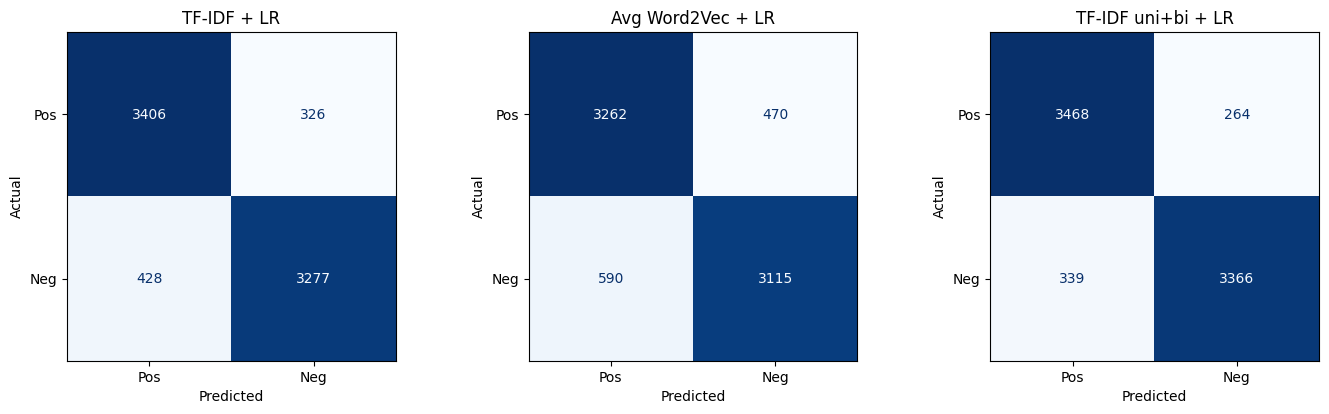

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (name, pred) in zip(axes, [("TF-IDF + LR", pred_lr), ("Avg Word2Vec + LR", pred_w2v), ("TF-IDF uni+bi + LR", pred_bi)]):
    cm = confusion_matrix(y_te, pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["Pos", "Neg"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [18]:
for name, pred in [("TF-IDF + LR", pred_lr), ("Avg Word2Vec + LR", pred_w2v), ("TF-IDF uni+bi + LR", pred_bi)]:
    tp, fn, fp, tn = confusion_matrix(y_te, pred, labels=[1, 0]).ravel()
    print(f"{name:20s} TP={tp} FN={fn} FP={fp} TN={tn} | loi tren Pos={fn/(tp+fn):.2%} Neg={fp/(fp+tn):.2%}")

TF-IDF + LR          TP=3406 FN=326 FP=428 TN=3277 | loi tren Pos=8.74% Neg=11.55%
Avg Word2Vec + LR    TP=3262 FN=470 FP=590 TN=3115 | loi tren Pos=12.59% Neg=15.92%
TF-IDF uni+bi + LR   TP=3468 FN=264 FP=339 TN=3366 | loi tren Pos=7.07% Neg=9.15%


Đọc confusion matrix: ở cả ba model, FP (negative bị đoán thành positive) nhiều hơn FN, nên class negative là class bị nhầm nhiều hơn và loại lỗi chiếm nhiều là false positive. Metric phản ánh vấn đề này là precision của class positive (thấp hơn recall). Average Word2Vec tăng lỗi ở cả hai class. Vì dataset cân bằng, accuracy và F1 cho cùng thứ tự xếp hạng, nhưng precision/recall cho biết model đang sai theo hướng nào.

## 8. Error analysis

In [19]:
test_out = test.assign(pred=pred_bi, p_pos=lr_bi.predict_proba(X_te_bi)[:, 1], n_words=test["text"].str.split().str.len())
test_out["true_lbl"] = test_out["label"].map({1: "positive", 0: "negative"})
test_out["pred_lbl"] = test_out["pred"].map({1: "positive", 0: "negative"})
wrong = test_out[test_out.label != test_out.pred]
right = test_out[test_out.label == test_out.pred]
print("So mau sai:", len(wrong), "| do dai trung binh mau sai:", round(wrong.n_words.mean(), 1), "| mau dung:", round(right.n_words.mean(), 1))

So mau sai: 603 | do dai trung binh mau sai: 223.0 | mau dung: 228.9


In [20]:
# 3 mau dung: chon mau model rat chac chan
show = ["true_lbl", "pred_lbl", "p_pos", "n_words", "text"]
correct_ex = pd.concat([right.nlargest(2, "p_pos"), right.nsmallest(1, "p_pos")])
display(correct_ex[show[:-1]])
for i, r in correct_ex.iterrows():
    print(f"[{i}] true={r.true_lbl} pred={r.pred_lbl} p_pos={r.p_pos:.4f}\n{r.text[:600]}\n")

,true_lbl,pred_lbl,p_pos,n_words
6797,positive,positive,0.999996,378
4452,positive,positive,0.999967,62
4520,negative,negative,0.000001,73


[6797] true=positive pred=positive p_pos=1.0000
this is one of bruce's most underrated films in my opinion, its an awesome heartwarming film, with a neat story and an amazing performance from bruce willis!. all the characters are great, and i thought willis and spencer breslin were just awesome together, plus bruce willis is simply amazing in this!. this is definitely one of bruce's best comedic performances (the waaaaaaaaaamabulance thing was great) and i thought it was very well written and made as well, plus the finale is especially cool!. it's good natured and it was cool how you can see russell's (willis) character change throughout th

[4452] true=positive pred=positive p_pos=1.0000
this is one of nine shorts on the anime disk, "the animatrix." it is my favorite. the artwork is amazing. the black-and-white, somewhat grainy texture perfectly captures the mood that the segment is trying to portray. the story is tight, and the ending is true to film noir. overall, i gave the animatr

In [21]:
# Mau sai: lay cac mau sai voi do tu tin cao nhat theo hai chieu va mot so mau sai ngan
wrong_conf = pd.concat([wrong.nlargest(4, "p_pos"), wrong.nsmallest(4, "p_pos")])
wrong_short = wrong.nsmallest(4, "n_words")
cand = pd.concat([wrong_conf, wrong_short])
display(cand[show[:-1]])
for i, r in cand.iterrows():
    print(f"[{i}] true={r.true_lbl} pred={r.pred_lbl} p_pos={r.p_pos:.3f}\n{r.text}\n")

,true_lbl,pred_lbl,p_pos,n_words
2402,negative,positive,0.999995,52
1028,negative,positive,0.998361,134
1057,negative,positive,0.993366,112
2529,negative,positive,0.987219,350
4203,positive,negative,0.005070,705
3806,positive,negative,0.006712,524
2707,positive,negative,0.016689,461
3517,positive,negative,0.016898,654
1291,negative,positive,0.924147,8
7021,positive,negative,0.059367,17


[2402] true=negative pred=positive p_pos=1.000
this is a great movie. i love the series on tv and so i loved the movie. one of the best things in the movie is that helga finally admits her deepest darkest secret to arnold!!! that was great. i loved it it was pretty funny too. it's a great movie! doy!!!

[1028] true=negative pred=positive p_pos=0.998
this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of britney, i love the five episodes. i was always being surprised by britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gentle and she loves her fans and we can see how she loves her work. i just don't give a 10 because of k-fed he his a real jerk he doesn't seem to like britney at all. i they make a second season of this great show because it shows at some people how britney really is. go britney your the best and you will never leave ou

Phân tích chi tiết từng mẫu ở file error_analysis.md.

## 9. Inspect model weights (TF-IDF unigram + LR)

In [22]:
coef = pd.Series(lr_uni.coef_[0], index=tfidf_uni.get_feature_names_out()).sort_values()
top = pd.DataFrame({
    "Top positive feature": coef.index[::-1][:20], "Weight (+)": coef.values[::-1][:20].round(3),
    "Top negative feature": coef.index[:20], "Weight (-)": coef.values[:20].round(3),
})
top

,Top positive feature,Weight (+),Top negative feature,Weight (-)
0,great,11.310,worst,-14.663
1,excellent,9.873,awful,-11.476
2,7,9.410,bad,-10.937
3,perfect,8.002,waste,-10.896
4,best,7.887,boring,-9.826
5,wonderful,7.247,poor,-8.042
6,favorite,7.020,nothing,-7.787
7,amazing,6.905,horrible,-7.664
8,brilliant,6.649,terrible,-7.583
9,hilarious,6.336,worse,-7.215


Phần lớn top feature có ý nghĩa cảm xúc rõ ràng (great, excellent, perfect, amazing, wonderful / worst, awful, waste, bad, boring, terrible), nên model học đúng tín hiệu của task. Một số feature không phải từ cảm xúc: "7", "8" là điểm số trong các cụm như "7/10", "8/10" bị tokenizer tách ra, chúng dự đoán tốt trên IMDb nhưng là đặc thù của domain review có chấm điểm và không tổng quát sang domain khác. "nothing" (nothing special, nothing happens), "supposed" (was supposed to be funny) chỉ mang nghĩa tiêu cực nhờ ngữ cảnh. "dvd", "well" là tương quan của dữ liệu chứ không phải cảm xúc, đây là dấu hiệu model học shortcut từ thống kê từ chứ không hiểu ngữ nghĩa.

In [23]:
cols_out = ["Representation", "Classifier", "C", "Vocabulary", "Vectorize time (s)", "Train time (s)", "Accuracy", "Precision", "Recall", "F1"]
res_df[cols_out].round(4).to_csv("results.csv", index=False)
pd.read_csv("results.csv")

,Representation,Classifier,C,Vocabulary,Vectorize time (s),Train time (s),Accuracy,Precision,Recall,F1
0,TF-IDF (unigram),Logistic Regression,4.00,57229,6.40,2.48,0.8986,0.8884,0.9126,0.9003
1,Avg Word2Vec (100d),Logistic Regression,4.00,60788,50.54,0.51,0.8575,0.8468,0.8741,0.8602
2,TF-IDF (unigram),Linear SVM,0.25,57229,6.40,1.01,0.8996,0.8896,0.9132,0.9012
3,TF-IDF (uni + bigram),Logistic Regression,16.00,553663,20.29,4.55,0.9189,0.9110,0.9293,0.9200
